### setting up and loading the data

In [1]:
# 08 · Monitoring, drift detection and retraining strategy (SCRUM-63)
%matplotlib inline
from pathlib import Path
import time, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path("/Users/uttamshrestha/Desktop/Data Science Practice Unit/PRT661-solar-forecasting")
RAW, PROC, OUT = REPO/"Datasets"/"raw", REPO/"Datasets"/"processed", REPO/"Outputs"
FIG = OUT/"figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 9,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

fc  = pd.read_parquet(PROC/"forecasts_calibrated.parquet")       # calibrated forecasts (notebook 06)
mm  = pd.read_parquet(PROC/"mastermeter1_hourly_clean.parquet")  # Master Meter 1 and weather (notebook 03)
sim = pd.read_parquet(PROC/"dispatch_hourly.parquet")            # site demand table (notebook 06)

# whole site solar from the 2024 and 2025 site telemetry, hourly
PV = "241_DKA_Totals_PV_Active_Power"
parts = [pd.read_csv(RAW/f"Alice_Springs_{yr}.csv", usecols=["timestamp", PV],
                     parse_dates=["timestamp"], low_memory=False) for yr in (2024, 2025)]
site_pv = (pd.concat(parts).drop_duplicates("timestamp").set_index("timestamp").sort_index()[PV]
             .pipe(pd.to_numeric, errors="coerce").resample("1h").mean().rename("site_pv"))

print(f"calibrated forecasts: {len(fc):,} rows, {fc.target_time.min():%Y-%m-%d} to {fc.target_time.max():%Y-%m-%d}")
print(f"site solar:           {len(site_pv):,} hours, {site_pv.index.min():%Y-%m-%d} to {site_pv.index.max():%Y-%m-%d}")


calibrated forecasts: 113,677 rows, 2019-01-01 to 2025-08-23
site solar:           17,568 hours, 2024-01-01 to 2026-01-01


### Daily performance monitoring

In [2]:
# 1 · Forecast performance monitoring (24 h ahead, daylight hours)
d24 = fc[(fc.horizon == 24) & (fc.is_daylight == 1) & fc.lo_c.notna()].copy()
d24["day"] = d24.target_time.dt.floor("D")
d24["abs_err"] = (d24.actual - d24.p50).abs()
d24["inside"] = d24.actual.between(d24.lo_c, d24.hi_c)

daily = d24.groupby("day").agg(mae=("abs_err", "mean"), mean_actual=("actual", "mean"),
                               coverage=("inside", "mean"), n=("actual", "size"))
daily = daily[daily.n >= 6].asfreq("D")                         # days with at least 6 daylight hours
roll = daily[["mae", "mean_actual", "coverage"]].rolling(30, min_periods=20).mean()
roll["nmae"] = roll.mae / roll.mean_actual                      # error relative to output, fair across seasons

# alert limits, fixed on the first two years only
REF = slice("2019-01-01", "2020-12-31")
nmae_limit = roll.loc[REF, "nmae"].quantile(0.99)
COV_LO, COV_HI = 0.70, 0.90
roll["alert_error"]    = roll.nmae > nmae_limit
roll["alert_coverage"] = (roll.coverage < COV_LO) | (roll.coverage > COV_HI)

print(f"monitoring {len(daily.dropna()):,} days of 24 h daylight forecasts, "
      f"{daily.index.min():%Y-%m-%d} to {daily.index.max():%Y-%m-%d}")
print(f"error alert: 30 day normalised MAE above {nmae_limit:.3f} (99th percentile of 2019 to 2020)")
print(f"coverage alert: 30 day coverage of the 80% interval outside {COV_LO:.2f} to {COV_HI:.2f}\n")

r = roll.dropna(subset=["nmae"])
summary = r.groupby(r.index.year).agg(days=("nmae", "size"), nmae=("nmae", "mean"), coverage=("coverage", "mean"),
                                      error_alert_days=("alert_error", "sum"),
                                      coverage_alert_days=("alert_coverage", "sum"))
print(summary.round(3).to_string())

# group consecutive alert days into episodes
ev = roll[roll.alert_error | roll.alert_coverage]
grp = ev.index.to_series().diff().ne(pd.Timedelta("1D")).cumsum()
episodes = ev.groupby(grp).apply(lambda g: pd.Series({
    "start": g.index.min(), "end": g.index.max(), "days": len(g),
    "type": "/".join(t for t, c in [("error", g.alert_error.any()), ("coverage", g.alert_coverage.any())] if c)}))
print(f"\nalert episodes: {len(episodes)}")
print(episodes.sort_values("days", ascending=False).head(8).to_string(index=False))

monitoring 2,375 days of 24 h daylight forecasts, 2019-01-02 to 2025-08-22
error alert: 30 day normalised MAE above 0.354 (99th percentile of 2019 to 2020)
coverage alert: 30 day coverage of the 80% interval outside 0.70 to 0.90

      days   nmae  coverage  error_alert_days  coverage_alert_days
day                                                               
2019   345  0.087     0.801                 0                    3
2020   366  0.135     0.795                 8                   15
2021   342  0.157     0.803                 3                   18
2022   365  0.176     0.800                 0                   13
2023   365  0.174     0.808                24                    7
2024   366  0.179     0.794                 8                    5
2025   234  0.138     0.797                 0                   18

alert episodes: 28
     start        end  days           type
2025-07-31 2025-08-16    17       coverage
2023-06-29 2023-07-12    14          error
2022-05-12 2022-05

### data drift detection

In [3]:
# 2 · Data drift check: site solar against Master Meter 1
sunny = mm.Global_Horizontal_Radiation > 300                    # clear daytime hours only
j = pd.concat([site_pv, mm.Active_Power.rename("mm1"), sunny.rename("sunny")], axis=1, sort=True)
j = j.loc["2024-01-01":"2025-08-22"]
j = j[(j.sunny == True) & (j.mm1 > 10) & (j.site_pv > 10)]
ratio = (j.site_pv / j.mm1).resample("D").median().dropna()

# reference fixed on the first four weeks of 2024; alert when the weekly median moves too far
REF_DAYS, TOL, PERSIST = 28, 0.20, 3
ref_med = ratio.iloc[:REF_DAYS].median()
r7  = ratio.rolling(7, min_periods=5).median()
dev = r7 / ref_med - 1
flag = dev.abs() > TOL
run = flag.groupby((~flag).cumsum()).cumsum()                   # consecutive flagged days
detect = run[run >= PERSIST].index.min()

print(f"reference: first {REF_DAYS} days of 2024, median site solar / Master Meter 1 = {ref_med:.2f}")
print(f"rule: 7 day median more than {TOL:.0%} from the reference for {PERSIST} days in a row")
print(f"drift detected on {detect:%d %b %Y}: 7 day median {r7[detect]:.2f} ({dev[detect]:+.0%})")

# after an alert the reference is re-fitted, as notebook 06 did by hand with K
after = ratio.loc[detect:]
new_ref = after.iloc[:REF_DAYS].median()
flagged_after = int(((after.rolling(7, min_periods=5).median() / new_ref - 1).abs() > TOL).sum())
print(f"re-baselined on the {REF_DAYS} days after detection: ratio {new_ref:.2f}")
print(f"days flagged after re-baselining (to Aug 2025): {flagged_after}")

reference: first 28 days of 2024, median site solar / Master Meter 1 = 2.24
rule: 7 day median more than 20% from the reference for 3 days in a row
drift detected on 28 Feb 2024: 7 day median 1.13 (-49%)
re-baselined on the 28 days after detection: ratio 1.14
days flagged after re-baselining (to Aug 2025): 0


### retraining strategy

In [4]:
# 3 · Retraining strategy for the demand model (from notebook 07)
from sklearn.ensemble import HistGradientBoostingRegressor

# same features as notebook 07, all known by 22:00 the evening before
dd = sim[["demand"]].copy()
dd["temp"] = mm.Weather_Temperature_Celsius.reindex(dd.index).interpolate(limit=6)
dd["temp"] = dd.temp.fillna(dd.groupby([dd.index.month, dd.index.hour]).temp.transform("mean"))
dd["lag24"], dd["lag48"], dd["lag168"] = dd.demand.shift(24), dd.demand.shift(48), dd.demand.shift(168)
dd["mean7"], dd["temp_lag24"] = sim.dem_fc, dd.temp.shift(24)
dd["hour"], dd["dow"], dd["month"] = dd.index.hour, dd.index.dayofweek, dd.index.month
dd["weekend"] = (dd.dow >= 5).astype(int)
FEATURES = ["lag24", "lag48", "lag168", "mean7", "temp_lag24", "hour", "dow", "weekend", "month"]
dd = dd.dropna(subset=["lag168"])

def fit(upto):
    tr = dd[dd.index < upto]
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
                                         l2_regularization=1.0, random_state=42).fit(tr[FEATURES], tr.demand)

TEST_START = "2024-07-01"
test = dd.loc[TEST_START:]
months = pd.period_range(TEST_START, dd.index.max(), freq="M")
def in_month(m): return test.index[(test.index >= m.start_time) & (test.index <= m.end_time)]
def month_mae(p, m):
    idx = in_month(m); idx = idx[idx.hour.isin(range(7, 16))]
    return (p[idx] - test.demand[idx]).abs().mean()

t0, preds, fits, log = time.time(), {}, {}, []

# (a) static: trained once on data to June 2024 and never updated
mdl = fit(months[0].start_time)
preds["static"] = pd.Series(mdl.predict(test[FEATURES]), test.index); fits["static"] = 1

# (b) scheduled: refit at the start of every month
p = pd.Series(index=test.index, dtype=float)
for m in months:
    mdl = fit(m.start_time); p[in_month(m)] = mdl.predict(test.loc[in_month(m), FEATURES])
preds["scheduled monthly"] = p; fits["scheduled monthly"] = len(months)

# (c) triggered: refit only when last month's error is more than 15% above the error after the last refit
TRIG = 1.15
p, mdl, n_fit, baseline = pd.Series(index=test.index, dtype=float), fit(months[0].start_time), 1, None
for k, m in enumerate(months):
    if k > 0:
        last = month_mae(p, months[k - 1])
        baseline = last if baseline is None else baseline
        if last > TRIG * baseline:
            mdl, n_fit, baseline = fit(m.start_time), n_fit + 1, None; log.append(str(m))
    p[in_month(m)] = mdl.predict(test.loc[in_month(m), FEATURES])
preds["triggered (error +15%)"] = p; fits["triggered (error +15%)"] = n_fit

plan_idx = test.index[test.index.hour.isin(range(7, 16))]
monthly = pd.DataFrame({k: [month_mae(v, m) for m in months] for k, v in preds.items()}, index=months.astype(str))
tab = pd.DataFrame({"planning_MAE_kW": {k: (v[plan_idx] - test.demand[plan_idx]).abs().mean() for k, v in preds.items()},
                    "worst_month_MAE_kW": monthly.max(), "model_fits": fits})
print(f"three retraining strategies, {TEST_START} to {test.index.max():%Y-%m-%d}, {time.time()-t0:.0f} s\n")
print(tab.round(1).to_string())
print(f"\ntriggered refits at the start of: {', '.join(log) if log else 'none'}")
print("\nplanning hour MAE by month (kW):")
print(monthly.round(1).to_string())

three retraining strategies, 2024-07-01 to 2025-08-22, 27 s

                        planning_MAE_kW  worst_month_MAE_kW  model_fits
static                             41.3                95.6           1
scheduled monthly                  24.9                53.9          14
triggered (error +15%)             29.1                59.9           3

triggered refits at the start of: 2024-11, 2025-01

planning hour MAE by month (kW):
         static  scheduled monthly  triggered (error +15%)
2024-07    22.3               22.3                    22.3
2024-08    18.5               17.7                    18.5
2024-09    17.6               16.7                    17.6
2024-10    49.0               26.1                    49.0
2024-11    54.6               29.7                    29.7
2024-12    67.2               53.9                    59.9
2025-01    86.4               39.8                    39.8
2025-02    95.6               25.9                    42.2
2025-03    66.8               24.4

### Figure 17, the monitoring view

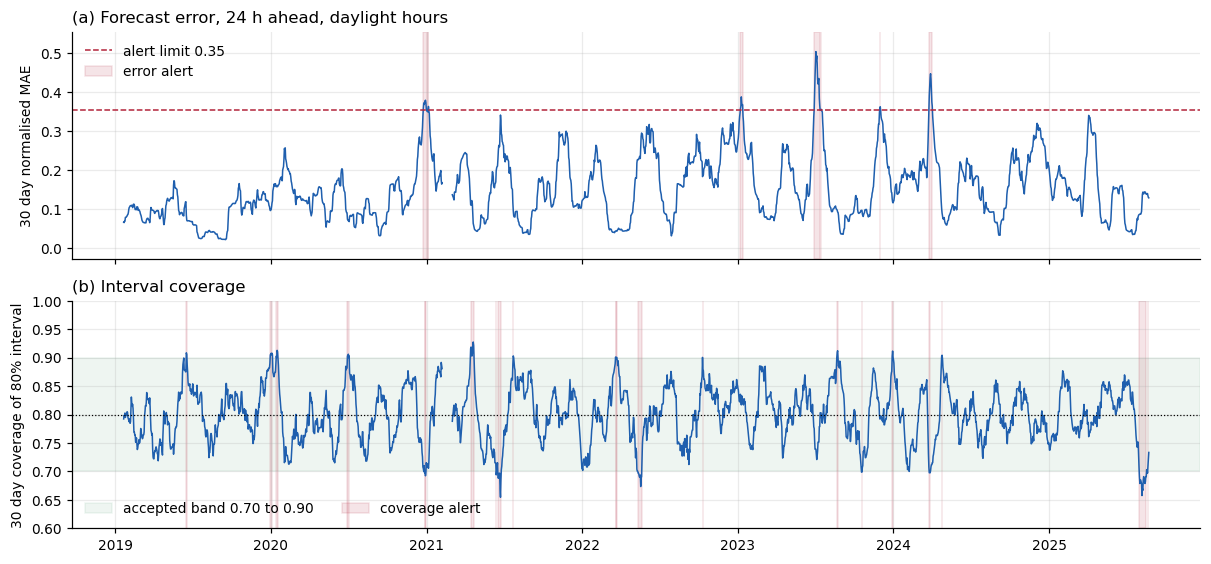

In [5]:
# 4 · Figure 17: what the monitor would have shown, 2019 to 2025
GREY, BLUE, ORANGE, RED = "#9AA3B0", "#1F5FAE", "#E08A1E", "#B3243B"

fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
ax[0].plot(roll.index, roll.nmae, color=BLUE, lw=1)
ax[0].axhline(nmae_limit, color=RED, ls="--", lw=1, label=f"alert limit {nmae_limit:.2f}")
ax[0].fill_between(roll.index, 0, 1, where=roll.alert_error, color=RED, alpha=.12,
                   transform=ax[0].get_xaxis_transform(), label="error alert")
ax[0].set_ylabel("30 day normalised MAE"); ax[0].legend(frameon=False, loc="upper left")
ax[0].set_title("(a) Forecast error, 24 h ahead, daylight hours", loc="left")

ax[1].plot(roll.index, roll.coverage, color=BLUE, lw=1)
ax[1].axhspan(COV_LO, COV_HI, color="#2E8B57", alpha=.08, label=f"accepted band {COV_LO:.2f} to {COV_HI:.2f}")
ax[1].axhline(0.80, color="black", lw=.8, ls=":")
ax[1].fill_between(roll.index, 0, 1, where=roll.alert_coverage, color=RED, alpha=.12,
                   transform=ax[1].get_xaxis_transform(), label="coverage alert")
ax[1].set_ylabel("30 day coverage of 80% interval"); ax[1].set_ylim(0.6, 1.0)
ax[1].legend(frameon=False, loc="lower left", ncol=2)
ax[1].set_title("(b) Interval coverage", loc="left")
fig.tight_layout(); fig.savefig(FIG/"fig17_monitoring.png"); plt.show()

### Figure 18 (drift and retraining), then save everything.

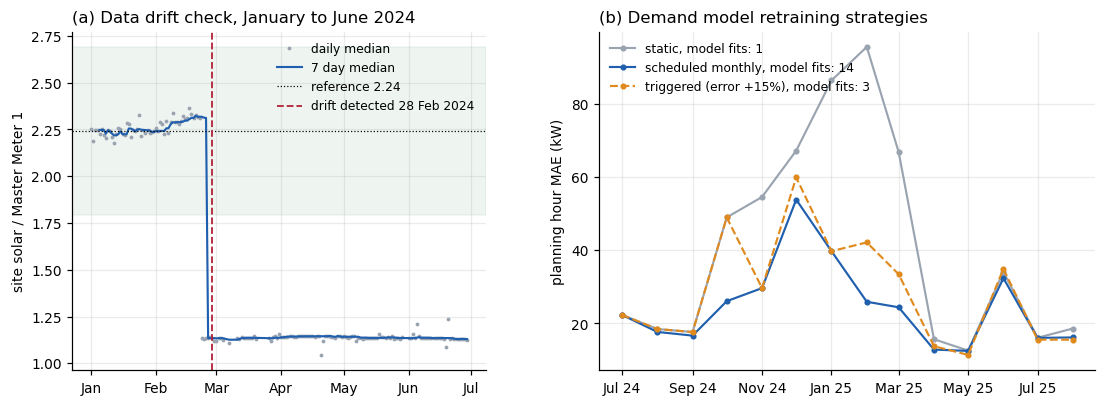

saved  monitoring_daily.parquet          107 kB
saved  monitoring_alerts.csv               1 kB
saved  monitoring_results.md               1 kB
saved  fig17_monitoring.png              159 kB
saved  fig18_drift_retraining.png         90 kB


In [6]:
# 5 · Figure 18: drift detection and retraining, then save the results
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.2], "wspace": 0.25})
part = ratio.loc[:"2024-06-30"]
ax[0].plot(part.index, part, ".", color=GREY, ms=3, label="daily median")
ax[0].plot(r7.loc[:"2024-06-30"].index, r7.loc[:"2024-06-30"], color=BLUE, lw=1.4, label="7 day median")
ax[0].axhline(ref_med, color="black", lw=.8, ls=":", label=f"reference {ref_med:.2f}")
ax[0].axhspan(ref_med * (1 - TOL), ref_med * (1 + TOL), color="#2E8B57", alpha=.08)
ax[0].axvline(detect, color=RED, lw=1.2, ls="--", label=f"drift detected {detect:%d %b %Y}")
ax[0].set_ylabel("site solar / Master Meter 1"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("(a) Data drift check, January to June 2024", loc="left")
ax[0].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))

x = pd.PeriodIndex(monthly.index, freq="M").to_timestamp()
for (name, col), color, ls in zip(monthly.items(), [GREY, BLUE, ORANGE], ["-", "-", "--"]):
    ax[1].plot(x, col, ls, color=color, lw=1.4, marker="o", ms=3,
               label=f"{name}, model fits: {tab.loc[name, 'model_fits']}")
ax[1].set_ylabel("planning hour MAE (kW)"); ax[1].legend(frameon=False, fontsize=8, loc="upper left")
ax[1].set_title("(b) Demand model retraining strategies", loc="left")
ax[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %y"))
fig.savefig(FIG/"fig18_drift_retraining.png", bbox_inches="tight"); plt.show()

# save: daily monitoring table (used by the dashboard), alert log, and a results summary
roll.to_parquet(PROC/"monitoring_daily.parquet")
episodes.to_csv(OUT/"monitoring_alerts.csv", index=False)

def md(df, digits=1):
    df = df.round(digits).reset_index()
    lines = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    return "\n".join(lines + ["| " + " | ".join(str(v) for v in r) + " |" for r in df.itertuples(index=False)])

report = f"""# Monitoring, drift detection and retraining (notebook 08)

## 1. Forecast performance monitoring
Daily checks on the 24 h ahead daylight forecasts, {daily.index.min():%d %b %Y} to {daily.index.max():%d %b %Y}.
Error alert: 30 day normalised MAE above {nmae_limit:.3f} (99th percentile of 2019 to 2020).
Coverage alert: 30 day coverage of the calibrated 80% interval outside {COV_LO:.2f} to {COV_HI:.2f}.

{md(summary.rename_axis("year"), 3)}

Alert episodes: {len(episodes)}, the longest {episodes.days.max()} days.

## 2. Data drift check
Reference: first {REF_DAYS} days of 2024, median site solar / Master Meter 1 = {ref_med:.2f}.
Rule: 7 day median more than {TOL:.0%} from the reference for {PERSIST} consecutive days.
Drift detected on {detect:%d %b %Y} (7 day median {r7[detect]:.2f}, {dev[detect]:+.0%}). Re-baselined ratio {new_ref:.2f};
{flagged_after} days flagged afterwards to August 2025.

## 3. Retraining strategy (gradient boosting demand model, {TEST_START} to {test.index.max():%d %b %Y})
{md(tab.rename_axis("strategy"))}

Triggered refits at the start of: {', '.join(log) if log else 'none'}.

Figures: fig17_monitoring.png, fig18_drift_retraining.png
"""
(OUT/"monitoring_results.md").write_text(report)
for p in [PROC/"monitoring_daily.parquet", OUT/"monitoring_alerts.csv", OUT/"monitoring_results.md",
          FIG/"fig17_monitoring.png", FIG/"fig18_drift_retraining.png"]:
    print(f"saved  {p.name:<28} {p.stat().st_size/1e3:8,.0f} kB")